# Modélisation — prédiction des six indicateurs thermiques

**Objectif.** Construire un modèle PyTorch qui prédit, à partir de $T_{int}(t)$ et de $U(t)$, les six indicateurs de l'énoncé : $HLC$, $HLC_{ext}$, $HLC_{mit}$ (W/K) et $\tau_b$, $\tau_n$, $\tau_\infty$ (h). Nous l'évaluons par cible et par famille, sur des données jamais vues. Nous analysons ensuite ses erreurs, et surtout leur origine.

**Ce que l'EDA a établi** (`01_eda.ipynb`), et qui guide la modélisation :
- les séries couvrent 8 h au pas d'une minute ; $U$ est un signal marche/arrêt (0 ou 7000 W) ;
- il n'existe que 2 798 signaux $U$ distincts, partagés entre simulations ; chaque simulation est en revanche un bâtiment distinct ;
- la contrainte $HLC = HLC_{ext} + HLC_{mit}$ est exacte, et $\tau_n < \tau_\infty < \tau_b$ dans 100 % des cas ;
- les constantes de temps suivent $\tau \approx C/HLC$ et dépassent presque toujours la fenêtre de 8 h : le régime permanent n'est jamais atteint.

**En bref.**
- **Modèle retenu :** un CNN-GRU multi-sorties, dont la tête de sortie garantit les contraintes physiques par construction.
- **Résultats sur le test :** le HLC est prédit avec une erreur relative moyenne de 8,3 % (R² = 0,43), contre 11,1 % pour la prédiction constante. Les scores sont au moins aussi bons sur des excitations jamais vues.
- **Origine de la limite :** elle tient aux données, pas au modèle. En 8 h, la température renseigne surtout sur la chaleur **stockée** par le bâtiment, et peu sur la chaleur **perdue**. La capacité apparente $C_n = \tau_n \cdot HLC$ est ainsi prédite avec un R² de 0,84, alors que le HLC plafonne près de 0,48, même à excitation fixée.

**Conventions.** Comme dans l'EDA :
- **[Assessment]** l'énoncé ;
- **[Article]** l'article de recherche de coEnergy sur l'identification du HLC, cité comme contexte physique ;
- **[Mesuré]** ce qui est calculé ici ;
- **[Hypothèse]** ce qui n'est pas vérifiable.

**Exécution.** Les modèles ont été entraînés sur GPU (Kaggle, Tesla T4) avec `python -m coenergy.train`. Les poids, métriques et prédictions sont dans `runs/`. Ce notebook ne fait que les relire : il s'exécute sur CPU. Seule la section 6 relit quelques batchs bruts, dans `data/quentin_house`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coenergy import identifiability as idf
from coenergy import results as rs
from coenergy.dataset import load_splits, split_table
from coenergy.eda import ensure_eda_results
from coenergy.evaluation import effective_capacities, excitation_groups, r2_by_group, regression_metrics
from coenergy.plots import SERIES, apply_style, plot_pred_vs_true

apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

per_sim = ensure_eda_results().per_sim          # descripteurs de l'EDA, une ligne par simulation
print("modèles disponibles :", rs.available_models())

modèles disponibles : ['mean', 'ridge', 'cnn', 'cnn_gru', 'cnn_free', 'cnn_hlc']


## 1. Protocole d'évaluation

**Question.** Comment mesurer la performance sans biais, alors que les excitations se répètent d'une simulation à l'autre ? Nous voulons aussi savoir si le modèle généralise à une excitation jamais vue.

**Découpage.** Il est figé dans `splits/split_seed42.npz` (un label par simulation) et construit par `coenergy.dataset.build_splits` :
- **test_new_u :** 5 % des signaux $U$ distincts (140 sur 2 798, graine 42, hors $U \equiv 0$) sont réservés. **Toutes** les simulations qui les portent, dans les 20 batchs, forment ce test. Ces excitations n'apparaissent nulle part ailleurs ;
- **train / val / test_random :** toutes les autres simulations, réparties par batchs entiers (1–16, 17–18, 19–20). L'EDA a montré que les batchs sont interchangeables et que chaque simulation est un bâtiment distinct : un découpage par batch ne laisse fuir aucune information sur le bâtiment.

In [2]:
split_table(load_splits())

,batchs,simulations,part (%)
jeu,,,
train,1–16,765063,76.506
val,17–18,95617,9.562
test_random,19–20,95565,9.556
test_new_u,1–20,43755,4.376
total,,1000000,100.000


**Prétraitement**, identique pour tous les jeux (`coenergy.dataset.preprocess_inputs`) :
- l'arrondi de l'énoncé est appliqué : $T$ à 0,01 °C, $U$ à 0,1 W **[Assessment]** ;
- les entrées sont $(T - T(0))/10\,\text{K}$ et $U/7000\,\text{W}$, sans décalage temporel ($T$ réagit au pas même de l'allumage, EDA 3.3) ;
- les cibles sont standardisées, avec le logarithme pour les $\tau$ (asymétriques, EDA 4.1). Moyennes et écarts-types sont ajustés **sur l'entraînement seul** et sauvegardés avec le modèle.

**Perte.** Erreur quadratique moyenne dans l'espace standardisé des cibles. Chaque famille de l'énoncé (HLC, Hb, CDT) pèse 1/3, répartie également entre ses cibles. Ainsi, les trois constantes de temps ne dominent pas le HLC.

**Métriques.** Aucune métrique ne suffit seule : chacune répond à une question différente. Toutes sont calculées en unités physiques, après transformation inverse (`coenergy.evaluation`), par cible et par famille.

| Métrique | Question à laquelle elle répond |
|---|---|
| MAE, RMSE (W/K, h) | Quelle erreur, dans l'unité du thermicien ? La RMSE pénalise davantage les grosses erreurs. |
| Erreur relative (%) | Quelle erreur rapportée à la taille du bâtiment ? 20 W/K d'écart n'ont pas le même poids pour un HLC de 120 ou de 360 W/K. |
| 95ᵉ percentile de l'erreur absolue (P95) | Quelle tolérance est respectée pour 95 % des bâtiments ? Pour un diagnostic, borner les mauvais cas importe autant que réduire l'erreur moyenne. |
| R² | Quelle part de la variabilité entre bâtiments le modèle explique-t-il ? Sans unité, il compare des cibles hétérogènes et se lit par rapport à la prédiction constante (R² = 0). |
| Contrôles physiques | Les prédictions respectent-elles la somme, l'ordre des $\tau$ et la positivité ? Une prédiction incohérente est inutilisable, même précise. |

**Capacités apparentes.** Nous évaluons aussi trois grandeurs dérivées des cibles prédites, sans les entraîner directement : $C_b = \tau_b \cdot HLC$, $C_n = \tau_n \cdot HLC$ et $C_\infty = \tau_\infty \cdot HLC$ (MJ/K).
- **Leur sens.** Pour un système thermique du premier ordre, la constante de temps vaut la capacité thermique divisée par la conductance : $\tau = C/H$. Le produit $\tau \cdot HLC$ est donc la chaleur que le bâtiment stocke par degré d'écart, sur l'échelle de temps de $\tau$.
- **Pourquoi elles éclairent le problème.** L'EDA a montré que $C_b$ est indépendante du HLC (corrélation −0,02, section 4.3). La section 6 montrera que c'est précisément $C_n$ que la courbe de température révèle le mieux.
- **Ce qui est mesuré et ce qui est interprété.** Le calcul est exact. Lire $C$ comme une « chaleur stockée » suppose le modèle du premier ordre ; un bâtiment réel possède plusieurs constantes de temps. D'où le qualificatif d'**apparentes**.

## 2. Modèles

**Question.** Quelle architecture exploite au mieux la structure du problème, et que gagne-t-on par rapport à des références simples ?

Tous les modèles reçoivent un tenseur $(n, 2, 480)$ et renvoient les six cibles en unités physiques. Le code est dans `coenergy.models` :

| Modèle | Structure | Ce qu'il mesure |
|---|---|---|
| `mean` | prédit la moyenne d'entraînement | le plancher : R² = 0 par construction |
| `ridge` | régression linéaire sur les 960 valeurs, résolue exactement, régularisation choisie sur la validation | ce qu'extrait un modèle linéaire |
| `cnn` | 8 blocs convolutifs résiduels à dilatations 1 à 128 (champ de vision ≈ 1 000 pas) ; résumé par moyenne et maximum ; tronc commun ; **tête physique** | modèle convolutif |
| `cnn_gru` | 2 blocs convolutifs (480 → 120 pas), puis GRU à 2 couches lu dans l'ordre du temps ; même tronc et même tête physique | architecture hybride : les convolutions extraient les réponses locales, le GRU accumule l'historique de l'excitation. C'est la famille d'architectures employée par coEnergy pour l'identification du HLC **[Article]** |
| `cnn_free` | `cnn` avec une tête libre (6 sorties indépendantes) | ablation : apport des contraintes |
| `cnn_hlc` | `cnn_free` entraîné sur le seul HLC | ablation : apport du multi-sorties, face à un modèle spécialisé sur l'indicateur principal |

**Le type de couches découle de l'EDA.**
- **Convolutions :** l'information sur le bâtiment se concentre dans les minutes qui suivent chaque commutation. Ce sont des motifs locaux, que les convolutions détectent.
- **Dilatations ou GRU :** ils relient chaque réponse à tout l'historique de l'excitation sur 8 h.
- **Canal « temps » en entrée :** à excitation égale, la position dans la fenêtre compte (dérive libre, état initial).
- **Tronc partagé :** les six cibles sont fortement liées entre elles ($\tau \approx C/HLC$).

**Les tailles** (64 canaux, 128 neurones) sont des valeurs courantes pour des séries de quelques centaines de pas. Elles sont volontairement modestes, pour comparer plusieurs architectures dans un budget de calcul fixé. La section 4.3 vérifie si un modèle quatre fois plus grand, ou un entraînement deux fois plus long, améliore les résultats.

**Coût de calcul.** Les deux réseaux ont un nombre de paramètres voisin, mais un coût très différent :

| | Opérations par simulation | Activations en mémoire |
|---|---|---|
| `cnn` : 16 convolutions sur les 480 pas | ≈ 95 millions | ≈ 520 000 valeurs |
| `cnn_gru` : 4 convolutions, puis un GRU sur 120 pas | ≈ 41 millions | ≈ 92 000 valeurs |

Le CNN-GRU réduit la longueur de la séquence avant ses couches les plus coûteuses. Il demande 2,3 fois moins de calcul et 5,7 fois moins de mémoire, ce qui explique son entraînement plus rapide (tableau ci-dessous).

**La tête physique** (`coenergy.models.PhysicalHead`) produit cinq valeurs brutes $a_1, \dots, a_5$, transformées ainsi :

$$HLC_{mit} = e^{a_1}, \quad HLC_{ext} = e^{a_2}, \quad HLC = HLC_{mit} + HLC_{ext}$$
$$\log\tau_n = a_3, \quad \log\tau_\infty = \log\tau_n + \text{softplus}(a_4), \quad \log\tau_b = \log\tau_\infty + \text{softplus}(a_5)$$

La somme de l'énoncé est donc **exacte par construction**, l'ordre $\tau_n < \tau_\infty < \tau_b$ est garanti, et toutes les sorties sont positives. Les $a_i$ sont recentrés sur les statistiques d'entraînement : un réseau non entraîné prédit déjà les bons ordres de grandeur.

**Entraînement** (`coenergy.train`) :
- 765 063 simulations, optimiseur AdamW, mini-lots de 1024, précision mixte ;
- **taux d'apprentissage en cycle unique** (*one-cycle*) : il monte jusqu'à $3 \cdot 10^{-3}$ pendant les premières époques, puis décroît jusqu'à presque zéro à la dernière époque. Ce calendrier converge vite et de façon stable. Il implique en revanche que le nombre d'époques est fixé à l'avance, et que des entraînements de durées différentes ne se comparent pas époque par époque ;
- **20 époques**, soit 15 millions d'exemples vus, un budget de 20 à 70 minutes par modèle sur un GPU T4. L'ablation `cnn_free` a d'abord été entraînée sur 12 époques, puis sur 20 pour une comparaison à budget égal (section 4.1) ;
- l'époque de plus faible perte de validation est conservée.

In [3]:
rs.training_table()

,rôle,paramètres,époques,meilleure époque,durée d'ajustement (min),GPU
mean,référence : moyenne d'entraînement,0,None,None,0.000,Tesla T4
ridge,référence : régression linéaire (ridge),5766,None,None,0.200,Tesla T4
cnn,"CNN dilaté, tête physique",234885,20,20,63.100,Tesla T4
cnn_gru,"CNN-GRU, tête physique (modèle retenu)",286789,20,20,19.100,Tesla T4
cnn_free,ablation : CNN sans contraintes physiques,235014,12,12,41.700,Tesla T4
cnn_hlc,ablation : CNN entraîné sur le seul HLC,235014,20,19,69.600,Tesla T4


**Lecture [Mesuré].** Le CNN-GRU s'entraîne **3,3 fois plus vite** que le CNN (19 min contre 63 min), alors qu'il compte 22 % de paramètres en plus. Le temps de calcul dépend de la longueur de la séquence traitée par chaque couche, bien plus que du nombre de paramètres (tableau du coût de calcul ci-dessus).

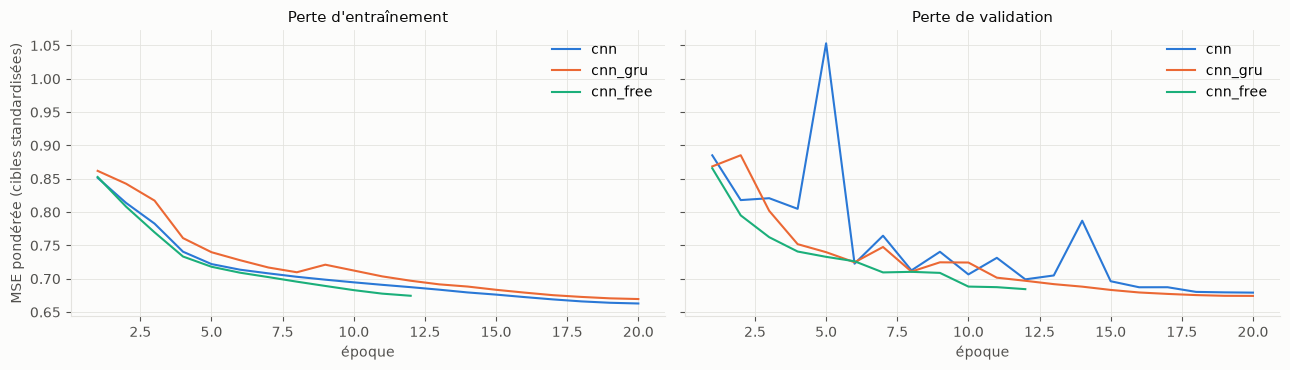

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for k, m in enumerate(["cnn", "cnn_gru", "cnn_free"]):
    h = rs.load_history(m)
    axes[0].plot(h["epoch"], h["train_loss"], color=SERIES[k], label=m)
    axes[1].plot(h["epoch"], h["val_loss"], color=SERIES[k], label=m)
axes[0].set_title("Perte d'entraînement"); axes[1].set_title("Perte de validation")
for ax in axes:
    ax.set_xlabel("époque"); ax.legend()
axes[0].set_ylabel("MSE pondérée (cibles standardisées)")
fig.tight_layout(); plt.show()

**Lecture [Mesuré].**
- Les pertes d'entraînement et de validation restent proches : **aucun sur-apprentissage**, ce qui est attendu avec 765 000 simulations pour moins de 300 000 paramètres.
- La meilleure époque est la dernière pour les trois réseaux : **l'entraînement n'a pas complètement convergé.**
- La courbe de validation du CNN-GRU est la plus régulière. Celle du CNN présente deux pics isolés (époques 5 et 14), sans conséquence sur le résultat, puisque l'époque retenue est la dernière.

- La courbe de `cnn_free` est sous les autres dès l'époque 2. C'est un effet du calendrier, pas une meilleure performance : sur 12 époques, le taux d'apprentissage monte puis redescend plus tôt. À une époque donnée, il est donc plus bas que pour un entraînement de 20 époques, et un taux plus bas donne une perte plus faible à court terme. Les valeurs finales se comparent correctement : 0,684 pour `cnn_free` (12 époques), 0,679 pour `cnn` et 0,674 pour `cnn_gru` (20 époques).

**Conséquence.** La dernière époque restant la meilleure, la question d'un entraînement plus long se pose. La section 4.3 y répond par l'expérience. `cnn_hlc` n'est pas tracé, car sa perte ne porte que sur le HLC et n'est pas comparable.

## 3. Résultats

### 3.1 Par cible

**Question.** Quel modèle prédit le mieux chaque indicateur, et que gagne-t-on par rapport aux références ?

In [5]:
r2 = rs.metric_table("test_random", "R²")
r2

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,C_b,C_n,C_inf
mean,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.016,-0.008,-0.011
ridge,0.260,0.208,0.060,-0.007,0.102,-0.003,0.208,0.702,0.251
cnn,0.428,0.275,0.462,0.126,0.257,0.095,0.383,0.834,0.368
cnn_gru,0.431,0.276,0.472,0.130,0.260,0.097,0.390,0.838,0.371
cnn_free,0.424,0.273,0.452,0.120,0.249,0.089,0.381,0.832,0.365
cnn_hlc,0.424,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
best = "cnn_gru"
p = rs.load_predictions(best, "test_random")
regression_metrics(p.y_true, p.y_pred)

,unité,RMSE,MAE,P95 |erreur|,erreur relative (%),R²
HLC,W/K,23.586,18.859,46.193,8.259,0.431
HLC_mit,W/K,22.342,17.971,43.533,15.797,0.276
HLC_ext,W/K,12.400,9.937,24.144,9.104,0.472
tau_b,h,9.445,7.352,18.417,14.800,0.130
tau_n,h,1.735,1.350,3.390,12.156,0.260
tau_inf,h,7.177,5.534,14.033,17.911,0.097


**Lecture [Mesuré]** (test_random, 95 565 simulations).
- **En unités physiques**, le CNN-GRU prédit le HLC à 18,9 W/K près en moyenne (MAE), soit 8,3 % d'erreur relative. 95 % des bâtiments sont estimés à moins de 46 W/K de leur vraie valeur. Pour $HLC_{ext}$, l'erreur relative est de 9,1 % ; pour $\tau_n$, de 12,2 %.
- **Les réseaux dépassent nettement les références.** Sur le HLC, l'erreur relative passe de 11,1 % (prédiction constante) à 9,5 % (ridge), puis 8,3 %, et le R² de 0,26 (ridge) à 0,43. Le gain est le plus fort sur $HLC_{ext}$ : R² de 0,06 avec la ridge, 0,47 avec le CNN-GRU. La signature de $HLC_{ext}$ dans la courbe dépend fortement de l'excitation, ce qu'un modèle linéaire unique ne peut pas représenter (section 6).
- **Ordre de difficulté :** le HLC et $HLC_{ext}$ sont les mieux prédits ; $HLC_{mit}$ et $\tau_n$ moyennement ; $\tau_b$ et $\tau_\infty$ très peu (R² ≈ 0,1). C'est l'ordre annoncé par l'EDA (section 5.2), à une exception près : $HLC_{ext}$ est mieux prédit que $HLC_{mit}$, alors que la corrélation linéaire suggérait l'inverse.
- **La capacité apparente $C_n = \tau_n \cdot HLC$ est très bien prédite** (R² = 0,84, erreur relative de 4,7 %), alors que $\tau_n$ ne l'est que faiblement (0,26). La section 6 explique cet écart, qui est au cœur du problème.
- **CNN et CNN-GRU sont équivalents en précision.** Leurs écarts sont de 0,01 ou moins sur toutes les cibles, trop faibles pour être interprétés avec un seul entraînement par modèle. L'écart ne tient pas non plus au nombre de paramètres : 22 % de plus pour le CNN-GRU, pour un R² supérieur de seulement 0,003 sur le HLC. Nous retenons le **CNN-GRU** pour son entraînement 3,3 fois plus rapide et sa convergence plus régulière, à précision égale.

### 3.2 Par famille de l'énoncé

In [7]:
rs.family_table("test_random")

HLC                         Hb                        CDT                    
             R² erreur relative (%)     R² erreur relative (%)     R² erreur relative (%)
mean     -0.000              11.124 -0.000              15.908 -0.000              16.898
ridge     0.260               9.476  0.134              14.516  0.031              16.103
cnn       0.428               8.324  0.368              12.589  0.159              15.040
cnn_gru   0.431               8.259  0.374              12.450  0.162              14.955
cnn_free  0.424               8.359  0.362              12.637  0.153              14.997
cnn_hlc   0.424               8.377 -0.068              16.488 -0.024              16.363

**Lecture [Mesuré].**

| Famille | R² moyen (CNN-GRU) | Erreur relative moyenne |
|---|---|---|
| HLC | 0,43 | 8,3 % |
| Hb | 0,37 | 12,5 % |
| CDT | 0,16 | 15,0 % |

Les constantes de temps forment la famille la plus difficile. Pour elle, l'erreur relative du modèle est à peine inférieure à celle de la prédiction constante (16,9 %).

### 3.3 Généralisation à des excitations jamais vues

**Question.** Le modèle se dégrade-t-il sur les 140 signaux $U$ réservés ?

In [8]:
pd.concat({s: rs.metric_table(s, "R²", ["ridge", "cnn", "cnn_gru"]) for s in rs.EVAL_SPLITS}, names=["jeu"])

HLC  HLC_mit  HLC_ext  tau_b  tau_n  tau_inf   C_b   C_n  C_inf
jeu                                                                                  
val         ridge   0.262    0.209    0.062 -0.005  0.098   -0.002 0.207 0.697  0.249
            cnn     0.430    0.274    0.462  0.130  0.255    0.098 0.384 0.832  0.368
            cnn_gru 0.433    0.276    0.473  0.134  0.259    0.100 0.390 0.836  0.371
test_random ridge   0.260    0.208    0.060 -0.007  0.102   -0.003 0.208 0.702  0.251
            cnn     0.428    0.275    0.462  0.126  0.257    0.095 0.383 0.834  0.368
            cnn_gru 0.431    0.276    0.472  0.130  0.260    0.097 0.390 0.838  0.371
test_new_u  ridge   0.277    0.222    0.060 -0.009  0.112   -0.002 0.213 0.750  0.265
            cnn     0.453    0.291    0.464  0.124  0.265    0.094 0.384 0.857  0.374
            cnn_gru 0.463    0.296    0.482  0.129  0.273    0.097 0.394 0.870  0.380

In [9]:
e = per_sim.loc[p.global_idx]
q = rs.load_predictions(best, "test_new_u")
active = ~e["all_off"].to_numpy()
pd.DataFrame({
    "test_random (tout)": regression_metrics(p.y_true, p.y_pred)["R²"],
    "test_random sans U ≡ 0": regression_metrics(p.y_true[active], p.y_pred[active])["R²"],
    "test_new_u": regression_metrics(q.y_true, q.y_pred)["R²"],
}).T.assign(**{"part U ≡ 0": [e["all_off"].mean(), 0.0, per_sim.loc[q.global_idx, "all_off"].mean()],
               "taux d'allumage moyen": [e["duty"].mean(), e.loc[active, "duty"].mean(),
                                         per_sim.loc[q.global_idx, "duty"].mean()]})

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,part U ≡ 0,taux d'allumage moyen
test_random (tout),0.431,0.276,0.472,0.130,0.260,0.097,0.087,0.466
test_random sans U ≡ 0,0.448,0.288,0.471,0.124,0.263,0.093,0.000,0.510
test_new_u,0.463,0.296,0.482,0.129,0.273,0.097,0.000,0.529


**Lecture [Mesuré].**
- Les scores sont **identiques en validation et en test**, et même un peu meilleurs sur test_new_u (HLC : 0,46 contre 0,43).
- Cet écart a une cause identifiable : test_new_u ne contient **aucune** simulation $U \equiv 0$ (le signal nul a été exclu de la réserve), alors qu'elles représentent 8,7 % de test_random et sont les moins bien prédites.
- **Sans les $U \equiv 0$, l'écart tombe à 0,015 sur le HLC** (0,448 contre 0,463). Le reste est cohérent avec le taux d'allumage plus élevé de test_new_u (0,53 contre 0,51), plus informatif (section 7.2).

**Conséquence.** Le modèle **généralise à des excitations jamais vues**, sans perte mesurable : il n'a pas mémorisé les 2 798 signaux de l'entraînement.

## 4. Ablations

**Question.** Les deux choix de conception, contraintes par construction et prédiction conjointe des six cibles, sont-ils justifiés par les mesures ?

### 4.1 Contraintes physiques

In [10]:
rs.physical_checks_table("test_random")

,|HLC - (HLC_mit + HLC_ext)| max (W/K),|résidu| relatif max,part avec tau_n < tau_inf < tau_b,part avec toutes les sorties > 0
mean,0.000,0.000,1.000,1.000
ridge,0.001,0.000,1.000,1.000
cnn,0.000,0.000,1.000,1.000
cnn_gru,0.000,0.000,1.000,1.000
cnn_free,0.510,0.002,1.000,1.000
cnn_hlc,84.105,0.487,1.000,1.000


**Lecture [Mesuré].**
- **Avec la tête physique** (`cnn`, `cnn_gru`), la somme est respectée à la précision float32 près (écart maximal de $1{,}5 \cdot 10^{-5}$ W/K), l'ordre des $\tau$ dans 100 % des cas, et toutes les sorties sont positives.
- **Sans contraintes** (`cnn_free`), la somme est violée jusqu'à 0,5 W/K (0,2 % du HLC). L'ordre des $\tau$ reste respecté de lui-même, tant les trois constantes sont naturellement séparées dans les données.
- **La précision est la même avec ou sans contraintes** : R² du HLC de 0,428 contre 0,424. La comparaison est légèrement défavorable à `cnn_free`, entraîné sur 12 époques au lieu de 20.

**Conséquence.** Les contraintes n'améliorent pas la précision, mais elles la **garantissent sans la dégrader**. Une prédiction qui ne respecte pas $HLC = HLC_{ext} + HLC_{mit}$ serait incohérente pour un utilisateur ; nous conservons donc la tête physique.

### 4.2 Un modèle multi-sorties ou un modèle par cible ?

In [11]:
rs.metric_table("test_random", "R²", ["cnn", "cnn_free", "cnn_hlc"], with_capacities=False)

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
cnn,0.428,0.275,0.462,0.126,0.257,0.095
cnn_free,0.424,0.273,0.452,0.120,0.249,0.089
cnn_hlc,0.424,NaN,NaN,NaN,NaN,NaN


**Lecture [Mesuré].**
- Spécialisé sur le seul HLC, le réseau obtient R² = 0,424, contre 0,428 pour le même réseau entraîné sur les six cibles.
- Les autres colonnes de `cnn_hlc` sont masquées : ses sorties non entraînées n'ont pas de sens (et sa somme est violée jusqu'à 84 W/K, section 4.1).

**Conséquence.** Prédire les six indicateurs ensemble **ne coûte rien sur le HLC** et fournit les cinq autres en plus. Un modèle unique multi-sorties est préférable à six modèles séparés : six fois moins de calcul, et une cohérence physique garantie.

## 5. Le resserrement des prédictions vers la moyenne

**Question.** À quoi ressemblent les erreurs ? Le modèle se trompe-t-il au hasard, ou de façon systématique ?

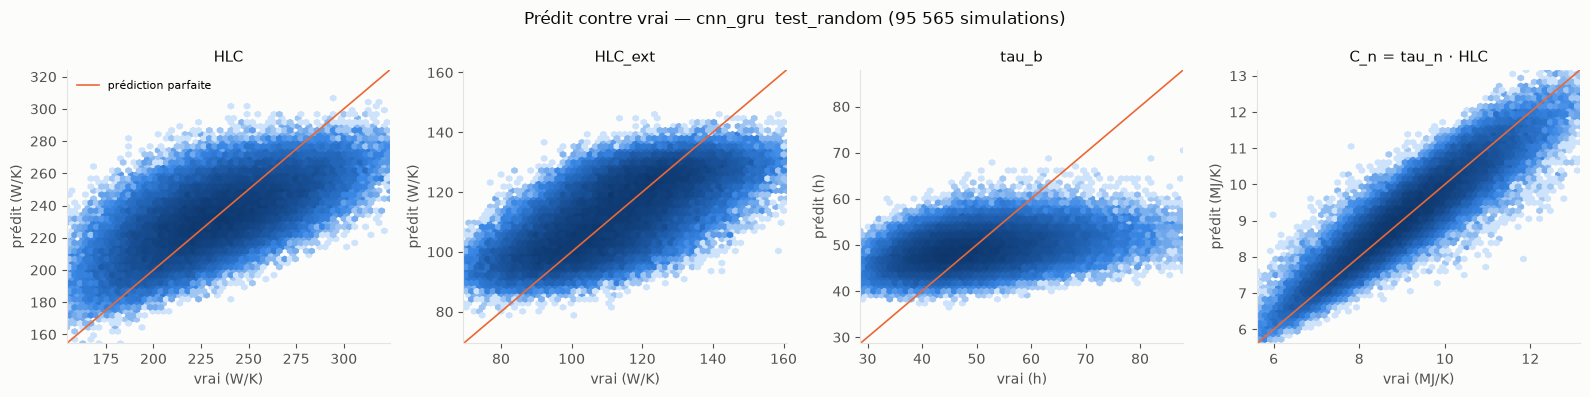

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
pente prédit ~ vrai,0.433,0.274,0.471,0.135,0.257,0.105
écart-type prédit / vrai,0.659,0.522,0.686,0.364,0.499,0.318


In [12]:
cap_true, cap_pred = effective_capacities(p.y_true), effective_capacities(p.y_pred)
panels = [(p.y_true[:, 0], p.y_pred[:, 0], "HLC", "W/K"),
          (p.y_true[:, 2], p.y_pred[:, 2], "HLC_ext", "W/K"),
          (p.y_true[:, 3], p.y_pred[:, 3], "tau_b", "h"),
          (cap_true[:, 1], cap_pred[:, 1], "C_n = tau_n · HLC", "MJ/K")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (yt, yp, title, unit) in zip(axes, panels):
    plot_pred_vs_true(ax, yt, yp, title, unit)
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle(f"Prédit contre vrai — {best}, test_random ({len(p.y_true):,} simulations)".replace(",", " "),
             color="#0b0b0b")
fig.tight_layout(); plt.show()
rs.shrinkage_table(p)

**Lecture [Mesuré].**
- Les nuages ne suivent pas la diagonale : ils sont **aplatis vers la moyenne**. La pente entre prédit et vrai vaut 0,43 pour le HLC et 0,14 pour $\tau_b$ ; elle est égale au R², à 0,01 près.
- À l'inverse, le nuage de $C_n$ suit la diagonale.
- **Interprétation.** C'est le comportement attendu d'un modèle qui minimise l'erreur quadratique quand les données ne suffisent pas à trancher. Face à une courbe compatible avec un HLC de 180 comme de 280 W/K, la meilleure réponse au sens quadratique est la valeur moyenne des bâtiments compatibles. Le modèle n'est pas biaisé : il est **prudent là où l'information manque**.

**Conséquence.** Les erreurs sont **systématiques** : surestimation des bâtiments très isolés, sous-estimation des moins isolés. Un modèle plus gros ne corrigera pas ce resserrement si l'information est absente des données. C'est l'objet de la section 6.

## 6. Pourquoi les R² ne dépassent pas ≈ 0,5 : identifiabilité

**Question.** Un R² de 0,43 sur le HLC est-il faible parce que le modèle est insuffisant, ou parce que les données ne contiennent pas davantage d'information ?

Pour répondre, il faut une **référence** : le meilleur score que l'on peut espérer avec ces données. Nous la mesurons dans le cadre le plus favorable, celui d'une excitation unique et connue à l'avance. C'est la situation d'un essai réel, pour lequel coEnergy entraîne un modèle dédié **[Article]**.

**Méthode** (`coenergy.identifiability`).
- **Le groupe étudié :** 14 670 simulations reçoivent **exactement le même signal U** (le signal non nul le plus fréquent, EDA 2.3). Entre elles, seuls le bâtiment et son état initial changent.
- **Trois mesures sur ce groupe**, chacune avec un ajustement sur 80 % des simulations et une évaluation sur les 20 % restants :
  1. **problème direct** : quelle part de la courbe $T(t)$ les six cibles expliquent-elles ?
  2. **problème inverse** : avec quel R² un réseau prédit-il chaque cible à partir de $T$ ? C'est la **performance de référence à excitation fixée** ;
  3. **corrélations canoniques** : combien de combinaisons indépendantes des paramètres du bâtiment $T$ permet-elle de lire ?
- **Le choix des modèles de référence.** Toutes les courbes du groupe partagent le même signal $U$. Il n'y a donc pas d'excitation à interpréter, et la courbe se traite comme un simple vecteur de 480 valeurs. Nous ajustons deux modèles adaptés à ce cadre, et retenons le meilleur pour chaque cible :
  - une **régression linéaire ridge**, avec une régularisation choisie par validation ;
  - un **perceptron multicouche** (MLP, 3 couches cachées de 512 neurones), qui teste si une relation non linéaire apporte davantage.
- **La limite de cette référence :** elle n'est **pas une borne mathématique**. Elle est obtenue avec un seul réseau et 11 700 simulations d'ajustement. Un meilleur modèle, ou plus de données, peut la dépasser légèrement. Elle donne l'ordre de grandeur de ce que permettent les données.

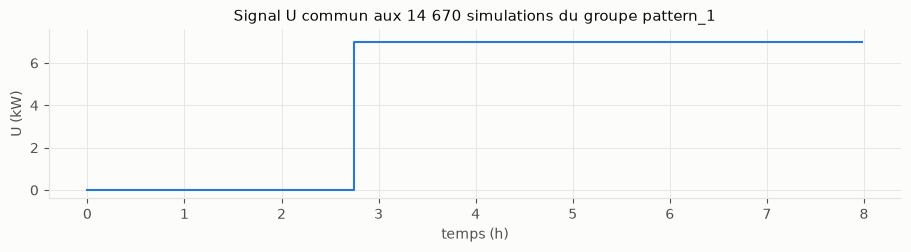

,pattern_1
part de la variance de T expliquée par les cibles,0.965
écart-type résiduel moyen (K),0.194
écart-type de T entre bâtiments (K),0.888
simulations,"14,670.000"


In [13]:
groups = idf.ensure_fixed_excitation(per_sim)      # extraction (≈ 30 s), puis cache dans outputs/identifiability
g = groups["pattern_1"]
fig, ax = plt.subplots(figsize=(11, 2.2))
ax.step(np.arange(480) / 60, g.u / 1000, where="post", color=SERIES[0])
ax.set_xlabel("temps (h)"); ax.set_ylabel("U (kW)"); ax.set_ylim(-0.4, 7.6)
ax.set_title(f"Signal U commun aux {len(g):,} simulations du groupe pattern_1".replace(",", " "))
plt.show()
idf.forward_explained_variance(g).to_frame("pattern_1")

**Lecture : problème direct [Mesuré].**
- Le signal commun est simple : aucune puissance pendant 2 h 45, puis 7 kW en continu jusqu'à la fin.
- À excitation fixée, **les six cibles expliquent 96,5 % de la variance de $T(t)$**. La courbe de température est donc presque entièrement déterminée par le bâtiment.
- L'écart résiduel (≈ 0,19 K) correspond à la dispersion de la réponse libre mesurée dans l'EDA (≈ 0,2 K, section 3.4). Nous l'attribuons à l'état initial aléatoire des parois **[Hypothèse H4]**.

Le problème direct (bâtiment → $T$) est bien posé. Reste à savoir si le problème inverse ($T$ → bâtiment) l'est aussi.

In [14]:
inv = pd.DataFrame({"ridge": idf.inverse_r2(g, "ridge"), "MLP": idf.inverse_r2(g, "mlp")}).T
display(inv)
cols = ["HLC", "HLC_mit", "HLC_ext", "C_n"]
pd.DataFrame({
    "référence à excitation fixée (meilleur des deux, pattern_1)":
        inv[["HLC", "HLC_mit", "HLC_ext", "log C_n"]].max().to_numpy(),
    f"{best}, toutes excitations (test_random)": r2.loc[best, cols].to_numpy(),
}, index=cols).T

,HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf,log C_b,log C_n,log C_inf
ridge,0.484,0.305,0.479,0.145,0.260,0.105,0.386,0.864,0.367
MLP,0.467,0.294,0.393,0.117,0.233,0.084,0.354,0.865,0.350


,HLC,HLC_mit,HLC_ext,C_n
"référence à excitation fixée (meilleur des deux, pattern_1)",0.484,0.305,0.479,0.865
"cnn_gru, toutes excitations (test_random)",0.431,0.276,0.472,0.838


**Lecture : problème inverse [Mesuré].**
- **Même dans le cadre le plus favorable, aucun des deux modèles ne dépasse R² ≈ 0,48 pour le HLC**, ni ≈ 0,15 pour $\log\tau_b$. La capacité apparente $C_n$ atteint en revanche ≈ 0,86.
- **La régression linéaire fait aussi bien que le MLP, et même un peu mieux.** À excitation fixée, la relation entre la courbe et les paramètres du bâtiment est donc presque linéaire. La non-linéarité vient de l'**interaction entre l'excitation et le bâtiment** : c'est pourquoi la ridge échoue sur des excitations mélangées (R² du HLC de 0,26, section 3.1), là où les réseaux réussissent.
- **Le CNN-GRU atteint presque la référence**, sans connaître l'excitation à l'avance, puisqu'il traite 2 798 signaux différents : 0,43 contre 0,48 pour le HLC, 0,47 contre 0,48 pour $HLC_{ext}$, 0,84 contre 0,86 pour $C_n$.
- Pour les $\tau$ et les capacités, la référence est calculée sur les logarithmes ; les valeurs restent comparables en ordre de grandeur.

In [15]:
cc = {}
for name, grp in groups.items():
    corr, weights = idf.canonical_correlations(grp)
    cc[name] = corr
display(pd.DataFrame(cc).T)
weights.round(2)

,combinaison 1,combinaison 2,combinaison 3,combinaison 4,combinaison 5
pattern_1,0.990,0.751,0.564,0.162,0.013
pattern_2,0.991,0.752,0.586,0.183,0.017


,log HLC_mit,log HLC_ext,log tau_b,log tau_n,log tau_inf
combinaison 1,0.960,0.610,0.010,1.000,-0.040
combinaison 2,-0.070,0.510,-0.500,-0.660,1.000
combinaison 3,0.380,0.020,1.000,-0.390,-0.280
combinaison 4,0.030,-0.200,-0.970,-0.300,1.000
combinaison 5,-0.120,-0.040,-0.760,-0.170,1.000


**Ce que mesure cette analyse.** Le bâtiment est décrit par cinq paramètres indépendants ($\log HLC_{mit}$, $\log HLC_{ext}$, $\log\tau_b$, $\log\tau_n$, $\log\tau_\infty$ ; le HLC n'en est pas un, puisqu'il en est la somme). L'analyse en corrélations canoniques cherche les **combinaisons pondérées** de ces paramètres que la courbe $T$ reflète le plus fidèlement, et mesure cette fidélité par une corrélation :
- proche de 1 : la combinaison se retrouve presque exactement à partir de $T$ ;
- proche de 0 : elle est invisible dans $T$.

Le premier tableau donne la corrélation de chaque combinaison, pour les deux groupes. Le second donne la composition de chaque combinaison : le poids de chaque paramètre, normalisé à 1 pour le plus important.

**Lecture : corrélations canoniques [Mesuré].**

| Combinaison | Corrélation | Composition principale | Lisible dans $T$ ? |
|---|---|---|---|
| 1 | 0,99 | $\log HLC_{mit}$, $\log HLC_{ext}$ et $\log\tau_n$ avec des poids voisins, soit ≈ $\log(HLC \cdot \tau_n) = \log C_n$ | presque parfaitement |
| 2 | 0,75 | $\tau_\infty$ opposée à $\tau_n$ et $\tau_b$, avec une part de $HLC_{ext}$ | partiellement |
| 3 | 0,56 | surtout $\tau_b$, avec une part de $HLC_{mit}$ | faiblement |
| 4 et 5 | ≈ 0,2 et ≈ 0 | combinaisons des constantes de temps | non |

- Les corrélations décroissent vite, de façon identique pour les deux groupes. $T$ permet donc de lire environ **deux à trois combinaisons** des cinq paramètres, et non chacun séparément.
- **La combinaison lue presque parfaitement est la capacité apparente mobilisée en 8 h, et non le HLC.**

**Interprétation physique.**
- **Ce que mesure un essai court.** Avec une fenêtre de 8 h, très inférieure aux constantes de temps ($\tau_b \approx 50$ h, EDA 4.4), la montée de température est dominée par le **stockage** de chaleur dans l'air et les parois, et peu par les **pertes** vers l'extérieur. Le HLC, grandeur d'équilibre, n'intervient qu'au second ordre.
- **Pourquoi le HLC reste ambigu.** Capacité et HLC ont été tirés indépendamment (EDA 4.3 : corr$(C_b, HLC) = -0{,}02$). Un bâtiment très isolé mais léger, et un bâtiment peu isolé mais lourd, produisent donc presque la même courbe.
- **Un constat connu.** Les méthodes d'essai court de la littérature font le même : la méthode QUB n'estime le HLC en une nuit qu'à environ 10 % près, **et seulement avec un protocole de chauffe et de refroidissement conçu pour cela**. L'article de coEnergy optimise lui-même l'excitation avant chaque essai **[Article]**.

**Conséquence.** Le R² modéré sur le HLC, et faible sur $\tau_b$ et $\tau_\infty$, **reflète l'information contenue dans 8 h de mesure** avec ces excitations, pas une insuffisance du modèle. Le CNN-GRU atteint l'ordre de grandeur de la référence à excitation fixée. Un gain important ne viendrait pas d'un autre réseau, mais d'une **information supplémentaire** : un essai plus long, ou une excitation conçue pour séparer stockage et pertes.

## 7. Analyse critique des erreurs

### 7.1 Les contrôles physiques

Section 4.1 : avec la tête physique, aucune prédiction ne viole la somme, l'ordre des $\tau$ ou la positivité, sur aucun jeu de test.

### 7.2 Selon le type d'excitation

**Question.** L'erreur dépend-elle de la richesse de l'excitation ? Les descripteurs sont calculés à partir de $U$, une entrée du modèle : ils sont disponibles au moment de la prédiction.

In [16]:
r2_by_group(p.y_true, p.y_pred, excitation_groups(e))

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf,simulations
U ≡ 0,0.246,0.144,0.485,0.190,0.227,0.140,"8,316.000"
1 commutation,0.475,0.305,0.530,0.148,0.288,0.108,"27,479.000"
2 commutations,0.452,0.291,0.485,0.130,0.266,0.098,"30,295.000"
3 à 10 commutations,0.427,0.271,0.427,0.111,0.238,0.081,"21,086.000"
plus de 10 commutations,0.396,0.255,0.308,0.051,0.212,0.043,"7,480.000"
"taux d'allumage < 0,3 (hors U ≡ 0)",0.412,0.253,0.485,0.175,0.254,0.127,"15,537.000"
"taux d'allumage 0,3 à 0,7",0.447,0.288,0.458,0.114,0.256,0.085,"55,475.000"
"taux d'allumage > 0,7",0.487,0.318,0.501,0.111,0.294,0.086,"16,237.000"


**Lecture [Mesuré].** Les R² sont calculés par rapport à la variance globale, pour être comparables d'un sous-ensemble à l'autre.
- **Les simulations $U \equiv 0$ sont les moins bien prédites pour le HLC** (0,25 contre 0,45 en moyenne pour les autres), comme l'EDA l'annonçait : sans chauffage, la réponse libre ne porte que peu d'information sur les déperditions. Elles sont conservées à l'entraînement et rapportées ici séparément.
- **Pour le HLC, les excitations simples et énergétiques sont les plus informatives** : un seul allumage (R² = 0,48), ou un taux d'allumage supérieur à 0,7 (0,49). À l'inverse, plus de 10 commutations donnent 0,40. Des blocs courts injectent la même énergie en créneaux trop brefs pour solliciter les parois.
- $HLC_{ext}$ fait exception : il est aussi bien prédit sans chauffage (0,49). La dérive libre de la température, pilotée par les échanges avec l'environnement, porte donc une information propre sur les déperditions vers l'extérieur.

**Conséquence.** Pour un protocole de mesure, ces résultats plaident pour une chauffe **longue et soutenue** plutôt que pour des commutations rapides. C'est cohérent avec le principe de la méthode QUB (une phase de chauffe suivie d'un refroidissement libre).

### 7.3 Les pires cas

In [17]:
rs.worst_cases_profile(p, e, target="HLC", quantile=0.99)

,simulations,erreur relative moyenne (%),HLC vrai moyen,HLC prédit moyen,part avec HLC vrai < 180 ou > 290,part U ≡ 0,taux d'allumage moyen,commutations (médiane)
1 % pires,956.000,35.831,175.526,237.678,0.620,0.132,0.423,2.000
toutes,"95,565.000",8.259,232.914,233.188,0.076,0.087,0.466,2.000


**Lecture [Mesuré].**
- Le 1 % de simulations aux plus fortes erreurs sur le HLC (erreur relative moyenne de 36 %) **ne se distingue presque pas par l'excitation** : même nombre médian de commutations, et à peine plus de $U \equiv 0$ (13 % contre 9 %).
- **Il se distingue par le bâtiment** : HLC vrai moyen de 176 W/K, alors que le modèle prédit 238 W/K, et 62 % de bâtiments hors de l'intervalle [180, 290] W/K, contre 8 % sur l'ensemble.

**Conséquence.** Les pires erreurs sont celles des **bâtiments extrêmes**, rapprochés de la moyenne par le resserrement décrit en section 5. Pour un usage opérationnel, le risque principal est de **sous-estimer l'écart à la moyenne** d'un bâtiment très performant ou très déperditif. Une estimation de l'incertitude associée à chaque prédiction limiterait ce risque.

## 8. Conclusion

**Résultats.**
- Le modèle retenu, un **CNN-GRU multi-sorties à tête physique**, prédit les six indicateurs en respectant **exactement** $HLC = HLC_{ext} + HLC_{mit}$ et $\tau_n < \tau_\infty < \tau_b$.
- Sur le test, il obtient un R² de 0,43 et une erreur relative de 8,3 % pour le HLC (contre 11,1 % pour une prédiction constante), avec un P95 de l'erreur absolue de 46 W/K. Il prédit très bien la capacité apparente $C_n$ (R² = 0,84), et faiblement $\tau_b$ et $\tau_\infty$ (R² ≈ 0,1).
- **Il généralise sans perte à des excitations jamais vues.**

**Décisions justifiées par les mesures.**

| Décision | Justification |
|---|---|
| Un modèle multi-sorties | il égale le modèle mono-cible sur le HLC et fournit les cinq autres indicateurs |
| Des contraintes par construction | elles garantissent la cohérence physique sans perte de précision |
| Le CNN-GRU plutôt que le CNN | précision équivalente, entraînement trois fois plus rapide |

**Ce qui limite la performance.** L'analyse d'identifiabilité montre que la limite tient aux **données**, et non au modèle :
- en 8 h, la température renseigne surtout sur la chaleur stockée, peu sur la chaleur perdue ;
- même à excitation fixée, aucun modèle de référence ne dépasse R² ≈ 0,48 sur le HLC ;
- le CNN-GRU atteint cet ordre de grandeur en traitant 2 798 excitations différentes.

**Limites de cette étude.**
- Chaque modèle a été entraîné une fois : des écarts inférieurs à 0,01, comme entre CNN et CNN-GRU, ne sont pas interprétables.
- La performance de référence est une estimation empirique, pas une borne théorique.
- Les simulations ne comportent ni bruit de capteur, ni variation des conditions extérieures **[Hypothèse H3]**. Sur des mesures réelles, les performances seraient vraisemblablement inférieures.
- L'entraînement n'a pas complètement convergé en 20 époques.

**Perspectives.**
- **Quantifier l'incertitude** de chaque prédiction, par exemple avec des intervalles calibrés par type d'excitation. C'est la réponse adaptée à une information intrinsèquement limitée.
- **Exploiter le modèle pour concevoir les protocoles.** L'erreur varie avec l'excitation (section 7.2) : un modèle entraîné peut servir à choisir, avant un essai, les excitations les plus informatives. C'est le principe de la conception d'excitations optimales développée par coEnergy **[Article]**.